# PACE: Predictive Allocation for Club Excellence
## Multi-Objective Optimization Analysis

**Student Name:** Justin Null
**Target Company/Industry:** Life Time Group Holdings (NYSE: LTH), premium health and fitness club operations
**Problem:** How should a Life Time center split its weekly flexible labor (floor staff, group fitness instructors, trainers on shift, childcare) between peak and off-peak hours?
**Objectives:** Minimize labor cost per member visit vs. maximize the Member Experience Score

---

### Project Overview

Life Time sells an experience, not a gym pass. Its center operations line, its largest cost, ran 51.6% of revenue in Q1 2026, and management tied part of the increase to busier clubs. Staffing every hour for the early-morning and evening rush protects the member experience that justifies premium dues ($930 average revenue per center membership in Q1 2026), but those same people sit idle at midday and inflate cost per visit. Trimming labor to the "average" day saves money but creates sold-out classes, unattended floors and childcare waitlists at exactly the moments members care about.

This notebook is the **optimization engine** for PACE. It simulates a representative center, evaluates **100 weekly staffing plans**, and maps the full Pareto frontier between "lean" and "luxurious". I control two **decision variables**:

| Decision variable | Range | Meaning |
|---|---|---|
| `peak_coverage_pct` | 60–150% | Staffing in peak windows (weekday 5–9 AM and 4–8 PM, weekend 8 AM–12 PM) as a % of the demand-based target |
| `offpeak_coverage_pct` | 40–130% | Staffing in all other open hours as a % of the same target |

Phase 2 will add the constraint-aware decision agent on top of this frontier.

In [1]:
# --- Setup: imports, plotting style, project paths -------------------------
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
IMG_DIR = PROJECT_ROOT / "images"
IMG_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Chart palette: colorblind-validated categorical hues and neutral ink
COLORS = {
    "frontier":  "#2a78d6",   # Pareto-optimal plans
    "strategy":  "#eb6834",   # highlighted strategic points
    "dominated": "#a3a29c",   # inefficient plans (recessive gray)
    "cost":      "#1baf7a",   # cost-efficiency series
    "experience":"#6250d6",   # member-experience series
    "ink":       "#0b0b0b",
    "ink_2":     "#52514e",
    "grid":      "#e4e3df",
}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["ink_2"], "axes.labelcolor": COLORS["ink"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_2"], "ytick.color": COLORS["ink_2"],
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold",
    "legend.frameon": False,
})
print("Environment ready | pandas", pd.__version__, "| numpy", np.__version__)

Environment ready | pandas 3.0.5 | numpy 2.5.3


## Section 1: Data Acquisition

**Strategy: synthetic data (LLM + Python), as approved in the proposal.** Individual clubs don't publish hourly traffic or shift data, so I prompted an LLM (Claude) to write a **seeded simulator** to my spec rather than paste a CSV by hand. A hand-typed CSV can't keep cost, hours and service levels arithmetically consistent, and it can't be reproduced. The exact prompt is in [`data/data_generation_prompt.txt`](data/data_generation_prompt.txt), and the calibration sources and validation notes are in [`data/DATA_SOURCE.md`](data/DATA_SOURCE.md).

How the simulator works ([`src/generate_data.py`](src/generate_data.py)):

1. **Demand.** It simulates 8 weeks × 7 days × 17 open hours of check-ins for one center: ≈4,410 memberships (837,903 center memberships ÷ 190 centers, Q1 2026) × 3.0 visits per week. Weekdays get a morning and an evening rush plus a lunch bump, and weekends get a late-morning peak. Week-, day- and hour-level noise means no two days repeat.
2. **Plans.** It scores every combination of the two coverage levels (10 × 10 = 100 plans) on the **same** 8 weeks (common random numbers), so differences between plans come from the decision, not from luck.
3. **Physics per hour.**
   - Floor help requests are an **M/M/c (Erlang C) queue**, which gives time-to-assistance.
   - Classes are capped at 3 studios × 35 spots, which gives fill rate and waitlist.
   - Childcare is capped at a 1:6 ratio with a two-adult minimum, which gives turnaways. A turned-away parent usually skips the visit.
4. **Cost.** Floor and childcare hours, plus pay per class, with 1.25× burden and 1.5× overtime past roster hours.

In [2]:
# Reproducibility check: regenerate the dataset from the seeded simulator and
# confirm it is identical to the committed CSV.
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from generate_data import build_dataset, PARAMS

regenerated, _ = build_dataset()
saved = pd.read_csv(DATA_DIR / "staffing_scenarios.csv")
pd.testing.assert_frame_equal(saved, regenerated, check_dtype=False, atol=1e-4)
print(f"Reproducibility check passed: simulator (seed={PARAMS['seed']}) reproduces "
      f"staffing_scenarios.csv exactly ({len(saved)} rows).")

Reproducibility check passed: simulator (seed=2026) reproduces staffing_scenarios.csv exactly (100 rows).


In [3]:
# Load the analysis dataset (one row per weekly staffing plan)
df = pd.read_csv(DATA_DIR / "staffing_scenarios.csv")
demand = pd.read_csv(DATA_DIR / "hourly_demand.csv")

# Names used throughout the notebook
DV1, DV2 = "peak_coverage_pct", "offpeak_coverage_pct"
OBJECTIVE_1 = "labor_cost_per_visit"       # MINIMIZE
OBJECTIVE_2 = "member_experience_score"    # MAXIMIZE
LABELS = {
    DV1: "Peak-hour staffing coverage (%)",
    DV2: "Off-peak staffing coverage (%)",
    OBJECTIVE_1: "Labor cost per member visit ($)",
    OBJECTIVE_2: "Member Experience Score (0-100)",
}

print("Data loaded successfully!")
print(f"Shape: {df.shape}   (simulated demand: {demand.shape[0]} center-hours)")
print("\nFirst 5 rows:")
df.head()

Data loaded successfully!
Shape: (100, 22)   (simulated demand: 952 center-hours)

First 5 rows:


,plan_id,peak_coverage_pct,offpeak_coverage_pct,labor_cost_per_visit,member_experience_score,weekly_labor_cost,weekly_visits,floor_staff_hours,childcare_staff_hours,classes_per_week,total_labor_hours,overtime_hours,assist_score,class_fit_score,childcare_score,avg_time_to_assist_min,peak_time_to_assist_min,avg_class_fill_rate,class_waitlist_per_week,childcare_turnaways_per_week,cost_per_visit_week_sd,mes_week_sd
0,P001,60,40,0.8619,45.7929,11378.7891,13202.135,262.0000,154.0625,41.000,457.0625,0.0,19.9769,43.5473,90.2424,12.2250,15.0963,0.9636,1531.8378,57.5789,0.0380,1.8323
1,P002,60,50,0.8685,46.3597,11465.9766,13202.135,262.1250,154.0625,42.500,458.6875,0.0,19.9769,45.1667,90.2424,12.2250,15.0963,0.9624,1483.0241,57.5789,0.0358,1.6936
2,P003,60,60,0.8834,47.4444,11662.8516,13202.135,262.4375,154.0625,45.875,462.3750,0.0,19.9769,48.2657,90.2424,12.2250,15.0963,0.9487,1391.4211,57.5789,0.0337,1.4878
3,P004,60,70,0.9079,48.6740,11986.2891,13202.135,263.0625,154.0625,51.375,468.5000,0.0,19.9769,51.7789,90.2424,12.2225,15.0963,0.9172,1265.3416,57.5789,0.0322,1.4837
4,P005,60,80,0.9251,49.3649,12212.6953,13202.135,263.7500,154.0625,55.125,472.9375,0.0,20.2109,53.4855,90.2424,12.1086,15.0963,0.8941,1189.5647,57.5789,0.0301,1.3848


## Section 2: Data Exploration

### 2.1 Data quality

In [4]:
# Missing values, data types, and basic statistics
print("Missing values (total across all columns):", int(df.isnull().sum().sum()))
print("\nData types:")
print(df.dtypes.value_counts().to_string())
print("\nBasic statistics (decision variables, objectives, key drivers):")
key_cols = [DV1, DV2, OBJECTIVE_1, OBJECTIVE_2, "weekly_labor_cost", "total_labor_hours",
            "avg_time_to_assist_min", "avg_class_fill_rate", "childcare_turnaways_per_week"]
df[key_cols].describe().T.round(2)

Missing values (total across all columns): 0

Data types:
float64    19
int64       2
str         1

Basic statistics (decision variables, objectives, key drivers):


,count,mean,std,min,25%,50%,75%,max
peak_coverage_pct,100.0,105.00,28.87,60.00,80.00,105.00,130.00,150.00
offpeak_coverage_pct,100.0,85.00,28.87,40.00,60.00,85.00,110.00,130.00
labor_cost_per_visit,100.0,1.22,0.20,0.86,1.07,1.23,1.37,1.64
member_experience_score,100.0,72.32,12.76,45.79,60.41,77.94,82.20,87.15
weekly_labor_cost,100.0,16207.38,2611.56,11378.79,14090.98,16237.21,18195.73,21778.36
total_labor_hours,100.0,599.62,83.25,457.06,531.30,595.50,669.38,762.44
avg_time_to_assist_min,100.0,5.20,3.67,1.52,2.66,3.33,7.82,12.22
avg_class_fill_rate,100.0,0.74,0.11,0.56,0.66,0.75,0.81,0.96
childcare_turnaways_per_week,100.0,18.73,23.12,0.00,0.04,3.59,43.33,57.58


In [5]:
# Verify the decision variables: ranges and full-grid coverage
print(f"Decision Variable 1 ({DV1}) range: {df[DV1].min()}% to {df[DV1].max()}%  "
      f"({df[DV1].nunique()} levels)")
print(f"Decision Variable 2 ({DV2}) range: {df[DV2].min()}% to {df[DV2].max()}%  "
      f"({df[DV2].nunique()} levels)")
print(f"\nTotal combinations: {len(df)}  (expected {df[DV1].nunique() * df[DV2].nunique()} for a full grid)")
print("Duplicate decision-variable pairs:", int(df.duplicated([DV1, DV2]).sum()))
print("Duplicate plan IDs:", int(df['plan_id'].duplicated().sum()))

Decision Variable 1 (peak_coverage_pct) range: 60% to 150%  (10 levels)
Decision Variable 2 (offpeak_coverage_pct) range: 40% to 130%  (10 levels)

Total combinations: 100  (expected 100 for a full grid)
Duplicate decision-variable pairs: 0
Duplicate plan IDs: 0


In [6]:
# Examine the objectives and confirm they trade off
print(f"Objective 1 ({OBJECTIVE_1}, minimize) range: ${df[OBJECTIVE_1].min():.3f} to ${df[OBJECTIVE_1].max():.3f}")
print(f"Objective 2 ({OBJECTIVE_2}, maximize) range: {df[OBJECTIVE_2].min():.1f} to {df[OBJECTIVE_2].max():.1f}")

correlation = df[OBJECTIVE_1].corr(df[OBJECTIVE_2])
print(f"\nCorrelation between objectives: {correlation:.3f}")
print("Because cost is MINIMIZED, a POSITIVE correlation is the tradeoff: buying experience costs money.")
print(f"(Equivalently, corr(-cost, experience) = {(-df[OBJECTIVE_1]).corr(df[OBJECTIVE_2]):.3f}, "
      "the negative sign the both-maximize convention expects.)")

Objective 1 (labor_cost_per_visit, minimize) range: $0.862 to $1.644
Objective 2 (member_experience_score, maximize) range: 45.8 to 87.2

Correlation between objectives: 0.849
Because cost is MINIMIZED, a POSITIVE correlation is the tradeoff: buying experience costs money.
(Equivalently, corr(-cost, experience) = -0.849, the negative sign the both-maximize convention expects.)


In [7]:
# Realism / calibration checks against Life Time's public Q1 2026 figures
memberships_per_center = PARAMS["center_memberships_total"] / PARAMS["centers"]
expected_visits = memberships_per_center * PARAMS["visits_per_membership_week"]
center_ops_per_center_week = 406.7e6 / PARAMS["centers"] / 13   # Q1 2026 center ops expense

print(f"Memberships per center (837,903 / 190): {memberships_per_center:,.0f}")
print(f"Expected weekly check-ins: {expected_visits:,.0f} | simulated mean completed visits: {df['weekly_visits'].mean():,.0f}")
print(f"Flexible labor per center-week: ${df['weekly_labor_cost'].min():,.0f} to ${df['weekly_labor_cost'].max():,.0f}")
print(f"  = {df['weekly_labor_cost'].min()/center_ops_per_center_week:.0%} to "
      f"{df['weekly_labor_cost'].max()/center_ops_per_center_week:.0%} of the ${center_ops_per_center_week:,.0f} "
      "center-operations line per center-week")

# The simulated demand curve should show two weekday rushes and a weekend late-morning peak
profile = (demand.assign(daytype=np.where(demand["is_weekend"], "Weekend", "Weekday"))
                 .groupby(["daytype", "hour"])["checkins"].mean().unstack(0).round(0))
print("\nPeak weekday hour:", profile["Weekday"].idxmax(), "| Peak weekend hour:", profile["Weekend"].idxmax())
print(f"Week-to-week spread of objectives (avg SD): cost/visit ${df['cost_per_visit_week_sd'].mean():.3f}, "
      f"experience {df['mes_week_sd'].mean():.2f} pts")

Memberships per center (837,903 / 190): 4,410
Expected weekly check-ins: 13,230 | simulated mean completed visits: 13,233
Flexible labor per center-week: $11,379 to $21,778
  = 7% to 13% of the $164,656 center-operations line per center-week

Peak weekday hour: 17 | Peak weekend hour: 10
Week-to-week spread of objectives (avg SD): cost/visit $0.027, experience 1.07 pts


### 2.2 How the decision variables drive each objective

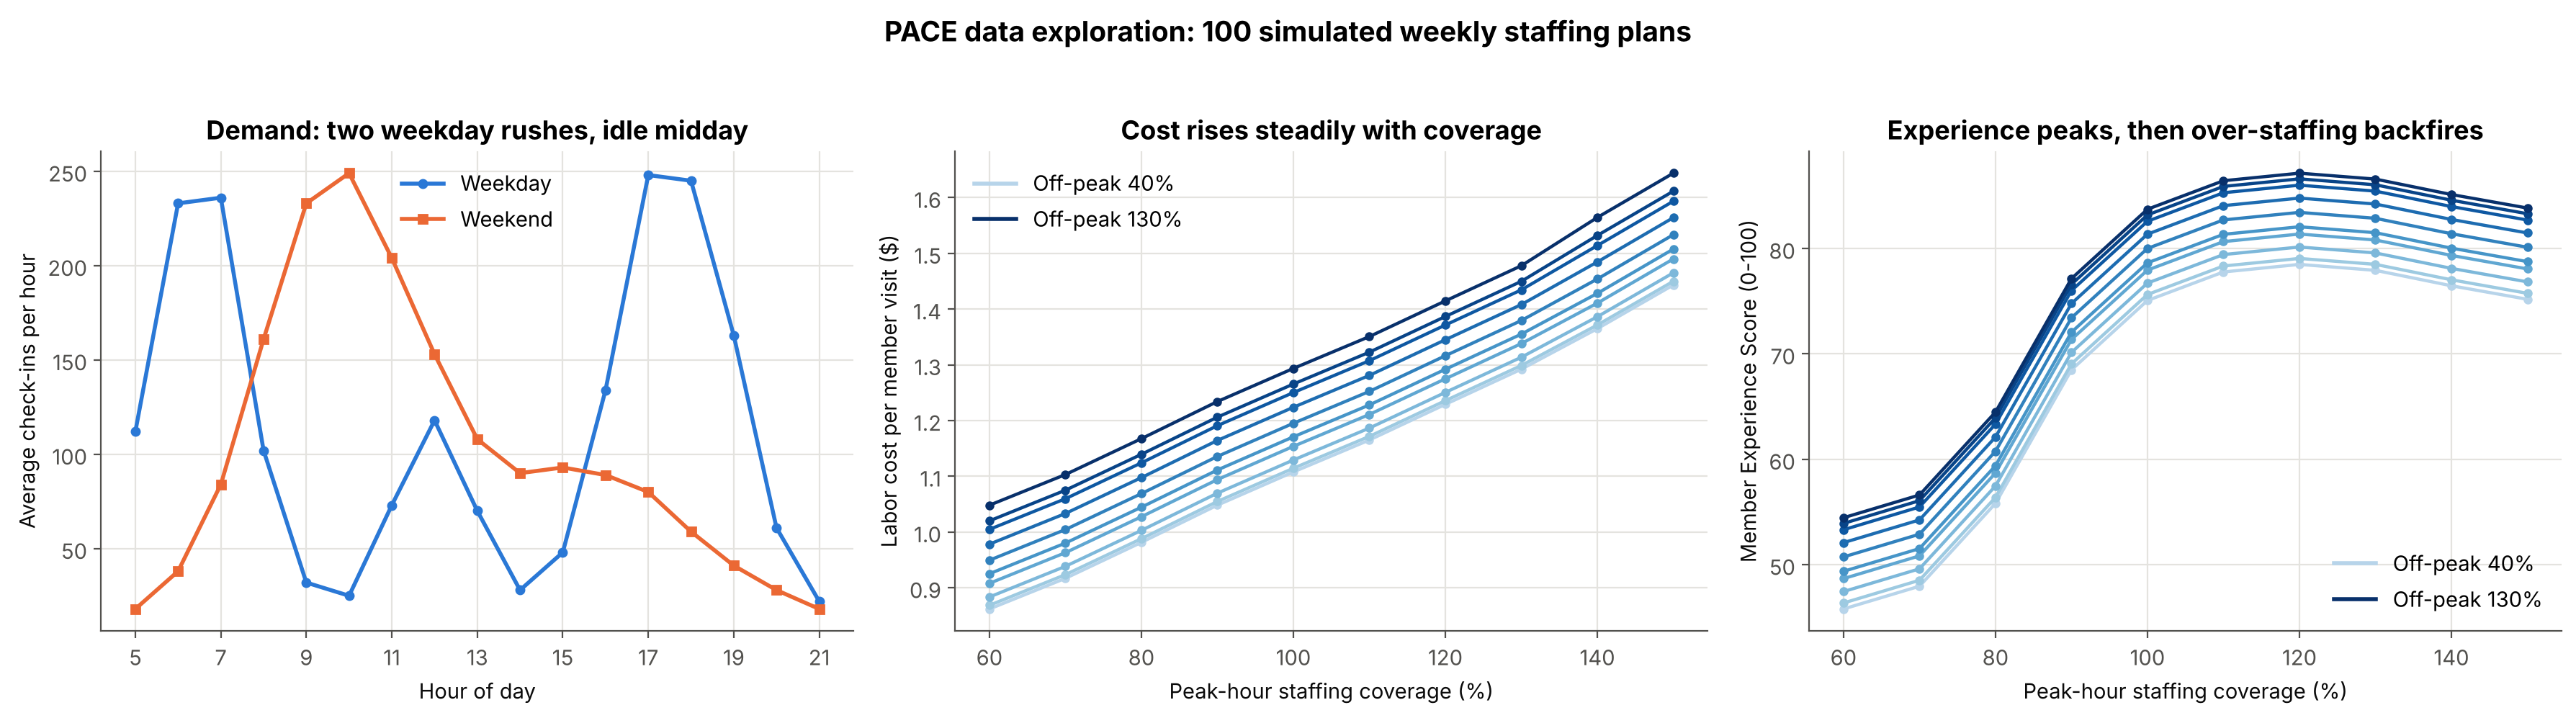

In [8]:
# Exploration figure: (a) demand context, (b)-(c) how the decision variables drive each objective
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (a) Demand context: the rush problem PACE is solving
ax = axes[0]
ax.plot(profile.index, profile["Weekday"], color=COLORS["frontier"], lw=2, marker="o", ms=4, label="Weekday")
ax.plot(profile.index, profile["Weekend"], color=COLORS["strategy"], lw=2, marker="s", ms=4, label="Weekend")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average check-ins per hour")
ax.set_title("Demand: two weekday rushes, idle midday")
ax.set_xticks(range(5, 22, 2))
ax.legend(loc="upper center")

# (b) and (c): each objective vs peak coverage, one line per off-peak level
cmap = plt.get_cmap("Blues")
offpeak_levels = sorted(df[DV2].unique())
for ax, obj in zip(axes[1:], [OBJECTIVE_1, OBJECTIVE_2]):
    for i, op in enumerate(offpeak_levels):
        sub = df[df[DV2] == op].sort_values(DV1)
        ax.plot(sub[DV1], sub[obj], color=cmap(0.3 + 0.7 * i / (len(offpeak_levels) - 1)),
                lw=1.6, marker="o", ms=3.5)
    ax.set_xlabel(LABELS[DV1])
    ax.set_ylabel(LABELS[obj])
# Sequential legend: light = low off-peak coverage, dark = high
handles = [Line2D([], [], color=cmap(0.3), lw=2, label=f"Off-peak {offpeak_levels[0]}%"),
           Line2D([], [], color=cmap(1.0), lw=2, label=f"Off-peak {offpeak_levels[-1]}%")]
axes[1].set_title("Cost rises steadily with coverage")
axes[1].legend(handles=handles, loc="upper left")
axes[2].set_title("Experience peaks, then over-staffing backfires")
axes[2].legend(handles=handles, loc="lower right")

fig.suptitle("PACE data exploration: 100 simulated weekly staffing plans", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(IMG_DIR / "data_exploration.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
# Experience components: what moves when coverage moves?
components = (df.groupby(DV1)[["assist_score", "class_fit_score", "childcare_score",
                               "avg_class_fill_rate", "peak_time_to_assist_min"]]
                .mean().round(2))
components.columns = ["Floor assist score", "Class fill-fit score", "Childcare score",
                      "Avg class fill rate", "Peak time-to-assist (min)"]
components

,Floor assist score,Class fill-fit score,Childcare score,Avg class fill rate,Peak time-to-assist (min)
peak_coverage_pct,,,,,
60,23.18,52.51,90.24,0.87,15.10
70,23.18,58.27,90.82,0.86,14.96
80,35.73,65.08,92.66,0.83,9.22
90,60.75,70.47,95.77,0.80,4.80
100,73.87,72.12,98.80,0.77,3.01
110,80.20,71.77,99.98,0.73,2.17
120,83.87,69.62,99.99,0.70,1.69
130,85.69,65.93,99.99,0.66,1.45
140,87.00,60.25,99.99,0.61,1.28


### Data exploration findings

* **Ranges are realistic.** Simulated completed visits average 13,233 per week, against an expected 13,230 (4,410 memberships × 3.0). Flexible labor runs $11.4k–$21.8k per center-week, 7–13% of Life Time's per-center-week center-operations expense. That fits, because the center-ops line also carries management, front desk, maintenance, PT commissions and utilities. The demand curve has the weekday 6–7 AM and 5–6 PM rushes and a 10 AM weekend peak that the proposal describes.
* **There is a clear tradeoff.** Cost per visit spans $0.86–$1.64 and experience spans 45.8–87.2. The correlation is +0.85, and since cost is minimized, that positive sign *is* the tradeoff: experience has to be bought.
* **The relationship is not linear, which is where the interesting decisions live.** Raising peak coverage from 70% to 100% is transformative. Peak time-to-assistance falls from about 15 minutes to 3, and the floor-assist score climbs from 23 to 74. Past roughly 120%, experience actually *falls* while cost keeps rising, because extra classes leave rooms half empty (fill rate drops from 77% at 100% coverage to 58% at 150%). Off-peak coverage behaves differently: it lifts experience steadily but modestly (about +8 points from 40% to 130%), since few members are in the building midday.
* **No data quality issues.** There are no missing values or duplicate plans, the 10 × 10 grid is complete, and the simulator reproduces the CSV exactly from its seed. Week-to-week noise is small relative to the differences between plans (SD about $0.03 per visit and about 1 experience point). This matches the proposal's expectation: staffing to the rush protects experience, while staffing beyond it only adds cost.

## Section 3: Pareto Frontier Calculation

**Dominance with mixed objective directions.** The guide's template assumes both objectives are maximized. PACE minimizes cost and maximizes experience, so I wrote the dominance test to take each objective's direction explicitly instead of hand-flipping signs:

> Plan **A dominates** plan **B** if A is *at least as good* on every objective (cost ≤, experience ≥) and *strictly better* on at least one.

A plan is **Pareto optimal** if no other plan dominates it. I implement the readable pairwise check (O(n²) loop, as in the guide) and an independent **vectorized NumPy** version, then assert that they agree. Two implementations that agree are a cheap but strong correctness check.

In [10]:
# Objective directions: the single source of truth for every Pareto calculation below
OBJECTIVES = {OBJECTIVE_1: "min", OBJECTIVE_2: "max"}


def dominates(a, b, objectives=OBJECTIVES):
    """
    Return True if solution `a` Pareto-dominates solution `b`.

    a, b : mapping (dict / Series) of objective column -> value
    objectives : dict of column -> "min" or "max"

    `a` dominates `b` when it is at least as good on every objective and
    strictly better on at least one.
    """
    strictly_better = False
    for col, sense in objectives.items():
        if sense == "min":
            a_better, a_worse = a[col] < b[col], a[col] > b[col]
        else:  # "max"
            a_better, a_worse = a[col] > b[col], a[col] < b[col]
        if a_worse:
            return False          # worse on any objective -> cannot dominate
        if a_better:
            strictly_better = True
    return strictly_better


def is_pareto_optimal(idx, df, objectives=OBJECTIVES):
    """
    Check if the row at `idx` is Pareto optimal (no other row dominates it).

    Parameters
    ----------
    idx : index label of the row to check
    df : DataFrame containing the objective columns
    objectives : dict of column -> "min" / "max"

    Returns
    -------
    bool : True if Pareto optimal, False if dominated
    """
    records = df[list(objectives)].to_dict("index")   # fast row access
    current = records[idx]
    for other_idx, other in records.items():
        if other_idx == idx:
            continue
        if dominates(other, current, objectives):
            return False      # found a plan that beats it -> dominated
    return True               # nothing beats it -> on the frontier


def pareto_mask(df, objectives=OBJECTIVES):
    """Vectorized Pareto check: boolean array, True = Pareto optimal."""
    # Convert every objective to "minimize" by flipping the sign of max-objectives
    X = np.column_stack([df[c].to_numpy() * (1 if s == "min" else -1)
                         for c, s in objectives.items()])
    no_worse = (X[:, None, :] <= X[None, :, :]).all(axis=2)   # [j, i]: j no worse than i everywhere
    better = (X[:, None, :] < X[None, :, :]).any(axis=2)      # [j, i]: j strictly better somewhere
    dominated = (no_worse & better).any(axis=0)                # any j dominates i
    return ~dominated

In [11]:
print("Calculating Pareto frontier...")
df["is_pareto_optimal"] = df.index.map(lambda idx: is_pareto_optimal(idx, df))

# Independent check: the vectorized implementation must agree row-for-row
assert (pareto_mask(df) == df["is_pareto_optimal"].to_numpy()).all(), "Implementations disagree!"

# For every plan, count how many other plans dominate it (0 = efficient)
X = np.column_stack([df[OBJECTIVE_1], -df[OBJECTIVE_2]])
df["n_dominated_by"] = ((X[:, None, :] <= X[None, :, :]).all(2) & (X[:, None, :] < X[None, :, :]).any(2)).sum(0)

pareto_df = df[df["is_pareto_optimal"]].copy()
dominated_df = df[~df["is_pareto_optimal"]].copy()

# Sanity checks on the result itself
assert not any(dominates(pareto_df.loc[i], pareto_df.loc[j])
               for i in pareto_df.index for j in pareto_df.index if i != j), "A frontier point is dominated!"
assert (pareto_df["n_dominated_by"] == 0).all()

print("\n=== PARETO FRONTIER RESULTS ===")
print(f"Total solutions analyzed: {len(df)}")
print(f"Pareto optimal solutions: {len(pareto_df)}")
print(f"Dominated solutions: {len(dominated_df)}")
print(f"Efficiency rate: {100 * len(pareto_df) / len(df):.1f}% of solutions are on the frontier")
print("Loop and vectorized implementations agree; no frontier point dominates another. ✓")

Calculating Pareto frontier...



=== PARETO FRONTIER RESULTS ===
Total solutions analyzed: 100
Pareto optimal solutions: 36
Dominated solutions: 64
Efficiency rate: 36.0% of solutions are on the frontier
Loop and vectorized implementations agree; no frontier point dominates another. ✓


In [12]:
# Where does inefficiency live? Share of plans on the frontier by peak-coverage level
by_peak = (df.groupby(DV1)
             .agg(plans=("plan_id", "size"),
                  on_frontier=("is_pareto_optimal", "sum"),
                  median_times_dominated=("n_dominated_by", "median"))
             .assign(frontier_share=lambda t: (t["on_frontier"] / t["plans"]).map("{:.0%}".format)))
by_peak

,plans,on_frontier,median_times_dominated,frontier_share
peak_coverage_pct,,,,
60,10,7,0.0,70%
70,10,2,2.0,20%
80,10,5,1.0,50%
90,10,4,2.0,40%
100,10,9,0.0,90%
110,10,7,0.0,70%
120,10,2,3.0,20%
130,10,0,10.0,0%
140,10,0,21.0,0%


In [13]:
# Frontier plans, ordered from leanest to most luxurious
frontier_cols = ["plan_id", DV1, DV2, OBJECTIVE_1, OBJECTIVE_2, "weekly_labor_cost", "total_labor_hours"]
pareto_df = pareto_df.sort_values(OBJECTIVE_1)
print(pareto_df[frontier_cols].round(3).to_string(index=False))

# Save the frontier for the Phase 2 decision agent
pareto_df.to_csv(DATA_DIR / "pareto_frontier.csv", index=False)
print(f"\nSaved {len(pareto_df)} efficient plans -> data/pareto_frontier.csv")

plan_id  peak_coverage_pct  offpeak_coverage_pct  labor_cost_per_visit  member_experience_score  weekly_labor_cost  total_labor_hours
   P001                 60                    40                 0.862                   45.793          11378.789            457.062
   P002                 60                    50                 0.868                   46.360          11465.977            458.688
   P003                 60                    60                 0.883                   47.444          11662.852            462.375
   P004                 60                    70                 0.908                   48.674          11986.289            468.500
   P005                 60                    80                 0.925                   49.365          12212.695            472.938
   P013                 70                    60                 0.938                   49.602          12391.641            484.312
   P006                 60                    90              

### Interpreting the frontier

* **36 of 100 plans (36%) are Pareto optimal and 64 are dominated.** That is lower than in a smooth textbook problem, and I expected it. Two forces create waste: (1) over-staffing peaks actively *hurts* experience (half-empty classes), so every plan at 130–150% peak coverage is dominated, by a median of 10 to 32 other plans; and (2) classes and staff come in whole or half units, so some coverage levels buy cost without a matching step up in service.
* **The frontier is concentrated at peak coverage of 100–110%** (16 of 20 plans are efficient there). At 100%, 9 of 10 off-peak levels are efficient. In other words, once the rush is staffed to target, the off-peak level is a legitimate "how much polish do we buy" choice.
* **Tradeoff structure: peaks first, then off-peak.** Walking the frontier from cheapest to richest, the big experience jumps come from raising *peak* coverage (60 → 80 → 90 → 100%). Off-peak coverage fills in the smaller steps between those jumps. Plans that spend on off-peak hours while the peaks are under-staffed (for example 60% peak with 110%+ off-peak) fall off the frontier. This is the proposal's "idle midday staff" problem, now quantified.

## Section 4: Strategic Analysis

## Section 5: Visualization